## IMPORT LIBRARY

In [523]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

LOAD DATASETS

In [524]:
df = pd.read_csv("dataset/olist_orders_dataset.csv")
df2 = pd.read_csv("dataset/olist_order_reviews_dataset.csv")
df3 =pd.read_csv("dataset/olist_order_items_dataset.csv")

In [525]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB
None


In [526]:
print(df2.info())

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.8 MB
None


In [527]:
df2.sample(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
72982,19290312247ac12772aa1672f8848d4f,c75be4dbb0444f5234b73d0e700bc425,1,NaN,O produto ainda não foi entregue.,2018-08-28 00:00:00,2018-08-28 20:45:41
97096,52205fa9b6f57bee4ebdd89ffd7e231f,eff853aac91ab73f53304207c4571d1f,5,NaN,NaN,2018-02-21 00:00:00,2018-02-21 22:33:30
67173,58dd0d28cb716f7c0f200a4321f12b9e,97d03d6144f96be066dcfb67ba92f4c5,3,NaN,faltou cupom fiscal,2017-08-01 00:00:00,2017-08-02 11:30:25
11854,b21d2923047ed85c4ce32008ac4fa0c8,843b7dada8b84daa895c7978c62f9e43,5,Preço Produto Prazo 10,Produto entregue antes do prazo prometido. Ist...,2018-08-03 00:00:00,2018-08-04 11:58:32
98403,96a3f13b17820de33189923b61fbc9e8,c7e9244a9fdf9ae33fd94f55e7e24741,5,super recomendo,"AMEI PEDIDO ENTREGUE BEM ANTES DO PRAZO ,TUDO ...",2018-08-31 00:00:00,2018-09-07 15:53:48


In [528]:
print(df3.info())

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 18.4 MB
None


## CEK MISSING VALUE, DUPLICATED, FEATURE SELECTION

### olist_orders_dataset

In [529]:
print("Missing value olist_orders_dataset:")
print(df.isnull().sum())
print("\nJumlah data duplikat:", df.duplicated().sum())

Missing value olist_orders_dataset:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Jumlah data duplikat: 0


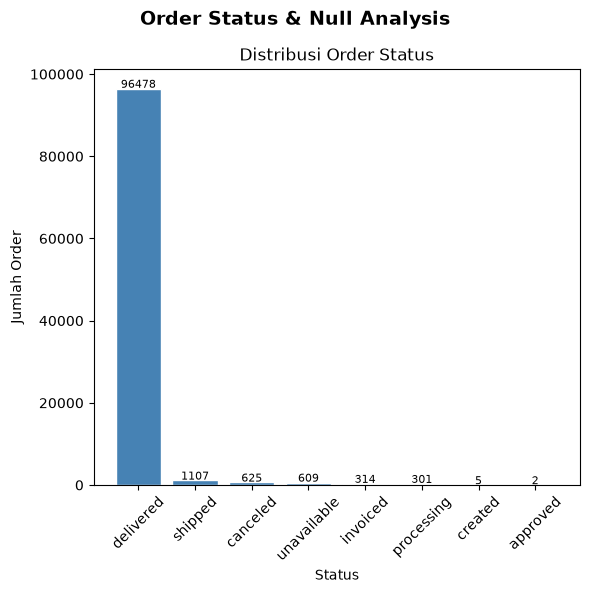

In [530]:
fig, ax = plt.subplots(figsize=(6, 6))
fig.suptitle("Order Status & Null Analysis", fontsize=14, fontweight="bold")

status_counts = df["order_status"].value_counts()

ax.bar(status_counts.index, status_counts.values, color="steelblue", edgecolor="white")
ax.set_title("Distribusi Order Status")
ax.set_xlabel("Status")
ax.set_ylabel("Jumlah Order")
ax.tick_params(axis="x", rotation=45)
for i, v in enumerate(status_counts.values):
    ax.text(i, v + 200, str(v), ha="center", fontsize=8)

plt.tight_layout()
plt.show()

In [531]:
features = ['order_id','order_purchase_timestamp', "order_approved_at", "order_delivered_customer_date", "order_estimated_delivery_date"]
df_filtered = df.loc[df["order_status"] == "delivered", features]

In [532]:
print(df_filtered.info())
print("\nCek Null:")
print(df_filtered.isnull().sum())
print("\nCek Duplicated:")
print(df_filtered.duplicated().sum())

<class 'pandas.DataFrame'>
Index: 96478 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       96478 non-null  str  
 1   order_purchase_timestamp       96478 non-null  str  
 2   order_approved_at              96464 non-null  str  
 3   order_delivered_customer_date  96470 non-null  str  
 4   order_estimated_delivery_date  96478 non-null  str  
dtypes: str(5)
memory usage: 14.4 MB
None

Cek Null:
order_id                          0
order_purchase_timestamp          0
order_approved_at                14
order_delivered_customer_date     8
order_estimated_delivery_date     0
dtype: int64

Cek Duplicated:
0


In [533]:
df_filtered = df_filtered.dropna()
df_filtered.isnull().sum()

order_id                         0
order_purchase_timestamp         0
order_approved_at                0
order_delivered_customer_date    0
order_estimated_delivery_date    0
dtype: int64

### olist_order_reviews_dataset

In [534]:
print("Missing value olist_order_reviews_dataset:")
print(df2.isnull().sum())
print("\nJumlah data duplikat:", df2.duplicated().sum())

Missing value olist_order_reviews_dataset:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Jumlah data duplikat: 0


In [535]:
df2_filtered = df2['review_score']

### olist_order_items_dataset

In [536]:
print("Missing value olist_order_items_dataset:")
print(df3.isnull().sum())
print("\nJumlah data duplikat:", df3.duplicated().sum())

Missing value olist_order_items_dataset:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Jumlah data duplikat: 0


In [537]:
print(df2[["review_score"]].describe())

       review_score
count  99224.000000
mean       4.086421
std        1.347579
min        1.000000
25%        4.000000
50%        5.000000
75%        5.000000
max        5.000000


In [538]:
df3_filtered = df3['shipping_limit_date']

## CEK OUTLIER

In [539]:
print(df3[["price", "freight_value"]].describe())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


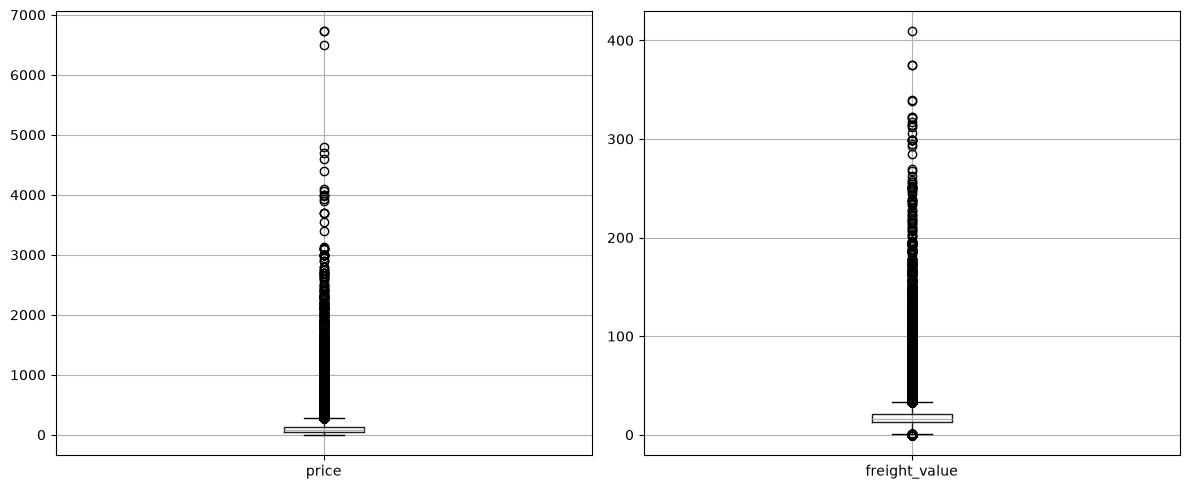

In [540]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df3.boxplot(column="price", ax=axes[0])
df3.boxplot(column="freight_value", ax=axes[1])
plt.tight_layout()
plt.show()

## FEATURE TERPILIH

In [541]:
print(df_filtered.info())

<class 'pandas.DataFrame'>
Index: 96456 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       96456 non-null  str  
 1   order_purchase_timestamp       96456 non-null  str  
 2   order_approved_at              96456 non-null  str  
 3   order_delivered_customer_date  96456 non-null  str  
 4   order_estimated_delivery_date  96456 non-null  str  
dtypes: str(5)
memory usage: 14.4 MB
None


In [542]:
print(df2_filtered.info())

<class 'pandas.Series'>
RangeIndex: 99224 entries, 0 to 99223
Series name: review_score
Non-Null Count  Dtype
--------------  -----
99224 non-null  int64
dtypes: int64(1)
memory usage: 775.3 KB
None


In [543]:
print(df3_filtered.info())

<class 'pandas.Series'>
RangeIndex: 112650 entries, 0 to 112649
Series name: shipping_limit_date
Non-Null Count   Dtype
--------------   -----
112650 non-null  str  
dtypes: str(1)
memory usage: 2.9 MB
None


## FEATURE ENGINEERING

In [557]:
date_columns = ['order_purchase_timestamp', 'order_approved_at'
                , 'order_delivered_customer_date', 
                'order_estimated_delivery_date']
for col in date_columns:
    df_filtered[col] = pd.to_datetime(df_filtered[col])


# Seberapa cepat order dikonfirmasi
df_filtered['approval_time'] = (
    df_filtered['order_approved_at'] - df_filtered['order_purchase_timestamp']
).dt.total_seconds() / 3600

# dari checkout sampai ke pelanggan (durasi nyata)
df_filtered['delivery_time'] = (
    df_filtered['order_delivered_customer_date'] - df_filtered['order_purchase_timestamp']
).dt.days

# estimasi dari eccomerce
df_filtered['estimated_delivery_days'] = (
     df_filtered["order_estimated_delivery_date"] - df_filtered["order_purchase_timestamp"]
).dt.days

# delivery di kurang estimasi, kalau minus lebih cepet, kalau plus telat
df_filtered['delivery_delay_days'] = (
    df_filtered['order_delivered_customer_date'] - df_filtered['order_estimated_delivery_date']
).dt.days

# is_late: 1 = terlambat, 0 = tepat waktu / lebih cepat
df_filtered['is_late'] = (df_filtered['delivery_delay_days'] > 0).astype(int)

# review score mean
review_agg = df2.groupby('order_id')['review_score'].mean()
# print(review_agg)

review_analysis = df_filtered[["order_id", "is_late"]].join(
    review_agg, on="order_id"
)

review_analysis.groupby("is_late")["review_score"].agg(
    jumlah_pesanan="count",
    rata_rata="mean",
    median="median",
).round(2)

,jumlah_pesanan,rata_rata,median
is_late,,,
0,89429,4.29,5.0
1,6381,2.27,1.0


## DISTRIBUSI IS_LATE

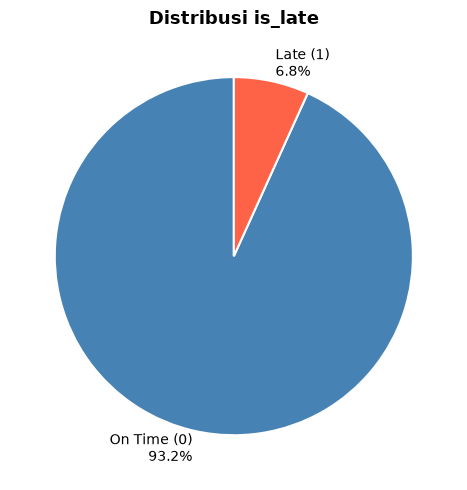

On Time : 89,922  (93.2%)
Late    : 6,534  (6.8%)


In [545]:
counts = df_filtered['is_late'].value_counts().sort_index()
labels = ['On Time (0)', 'Late (1)']
colors = ['steelblue', 'tomato']

plt.figure(figsize=(5, 5))
plt.pie(
    counts.values,
    labels=[f'{l}\n{v/counts.sum()*100:.1f}%' for l, v in zip(labels, counts.values)],
    colors=colors,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Distribusi is_late', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"On Time : {counts[0]:,}  ({counts[0]/counts.sum()*100:.1f}%)")
print(f"Late    : {counts[1]:,}  ({counts[1]/counts.sum()*100:.1f}%)")

In [546]:
# 2. Merge df3 (harus setelah datetime dikonversi)
shipping = df3.groupby("order_id")["shipping_limit_date"].min().reset_index()
shipping["shipping_limit_date"] = pd.to_datetime(shipping["shipping_limit_date"])
df_filtered = df_filtered.merge(shipping, on="order_id", how="left")

# 3. Buat semua fitur
df_filtered['seller_deadline_gap'] = (
    df_filtered['shipping_limit_date'] - df_filtered['order_purchase_timestamp']
).dt.days


display(df_filtered.head(100))  

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date,approval_time,delivery_time,estimated_delivery_days,delivery_delay_days,is_late,shipping_limit_date,seller_deadline_gap
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-10 21:25:13,2017-10-18,0.178333,8,15,-8,0,2017-10-06 11:07:15,4
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-08-07 15:27:45,2018-08-13,30.713889,13,19,-6,0,2018-07-30 03:24:27,5
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-17 18:06:29,2018-09-04,0.276111,9,26,-18,0,2018-08-13 08:55:23,5
3,949d5b44dbf5de918fe9c16f97b45f8a,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-12-02 00:28:42,2017-12-15,0.298056,13,26,-13,0,2017-11-23 19:45:59,5
4,ad21c59c0840e6cb83a9ceb5573f8159,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-16 18:17:02,2018-02-26,1.030556,2,12,-10,0,2018-02-19 20:31:37,5
...,...,...,...,...,...,...,...,...,...,...,...,...
95,6a0a8bfbbe700284feb0845d95e0867f,2017-11-22 11:32:22,2017-11-22 11:46:50,2017-12-28 19:43:00,2017-12-11,0.241111,36,18,17,1,2017-11-28 11:46:50,6
96,f7959f8385f34c4f645327465a1c9fc4,2017-03-30 07:50:33,2017-03-30 08:05:08,2017-04-10 02:59:52,2017-04-26,0.243056,10,26,-16,0,2017-04-11 08:05:08,12
97,23f553848a03aaab35bb3f9f87725125,2018-06-05 09:10:34,2018-06-05 09:32:22,2018-06-18 12:36:54,2018-07-23,0.363333,13,47,-35,0,2018-06-15 09:31:23,10
98,e3447938231fb6ba2fee0231b51eca59,2018-08-26 11:04:26,2018-08-26 11:15:29,2018-08-28 21:06:31,2018-08-30,0.184167,2,3,-2,0,2018-08-28 11:15:29,2


### TRAIN TEST SPLIT

In [547]:
X = df_filtered[["estimated_delivery_days", "approval_time", "seller_deadline_gap"]]
# X = df_filtered[["estimated_delivery_days", "approval_time"]]
y = df_filtered["is_late"]

In [548]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [549]:
print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test : {y_test.shape}")
print(f"\nDistribusi is_late di train:\n{y_train.value_counts()}")
print(f"\nDistribusi is_late di test:\n{y_test.value_counts()}")

X_train: (77164, 3)
X_test : (19292, 3)
y_train: (77164,)
y_test : (19292,)

Distribusi is_late di train:
is_late
0    71917
1     5247
Name: count, dtype: int64

Distribusi is_late di test:
is_late
0    18005
1     1287
Name: count, dtype: int64


## Modeling

Model memprediksi status keterlambatan pesanan. Untuk setiap algoritma, Grid Search membandingkan enam kombinasi parameter melalui validasi silang tiga fold pada data latih. Kriteria pemilihannya adalah rata-rata F1 kelas terlambat. Grid Search kemudian melatih ulang konfigurasi terpilih pada seluruh data latih.

### Random Forest

Random Forest menggabungkan prediksi banyak pohon untuk menangkap hubungan antara durasi persetujuan, estimasi pengiriman, dan tenggat penjual. Bobot kelas seimbang memberi pesanan terlambat pengaruh lebih besar saat pelatihan. Dengan jumlah pohon tetap 100, pencarian menguji kedalaman pohon dan jumlah minimum pesanan pada setiap daun untuk mengendalikan kompleksitas model.

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV

rf_search = GridSearchCV(
    RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
    ),
    param_grid={
        "max_depth": [3, 5, 8],
        "min_samples_leaf": [5, 20],
    },
    scoring="f1",
    cv=3,
    n_jobs=2,
)
rf_search.fit(X_train, y_train)
rf_final = rf_search.best_estimator_

print("Parameter terpilih:", rf_search.best_params_)
print("F1 Late validasi:", round(rf_search.best_score_, 3))
print(classification_report(
    y_test, rf_final.predict(X_test), labels=[0, 1],
    target_names=["On Time", "Late"], zero_division=0,
))

Parameter terpilih: {'max_depth': 8, 'min_samples_leaf': 20}
F1 Late validasi: 0.155
              precision    recall  f1-score   support

     On Time       0.96      0.47      0.63     18005
        Late       0.09      0.70      0.15      1287

    accuracy                           0.49     19292
   macro avg       0.52      0.59      0.39     19292
weighted avg       0.90      0.49      0.60     19292



### XGBoost

XGBoost menambahkan pohon secara bertahap untuk memperbaiki prediksi dari pohon sebelumnya. Rasio kelas pada data latih memberi bobot lebih besar pada kelas terlambat. Grid Search menguji kedalaman pohon dan laju pembelajaran untuk memilih seberapa rumit setiap pohon dan seberapa besar kontribusinya pada prediksi akhir.

In [29]:
from xgboost import XGBClassifier

# Rasio pesanan tepat waktu terhadap pesanan terlambat pada data latih.
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb_search = GridSearchCV(
    XGBClassifier(
        n_estimators=100,
        scale_pos_weight=scale,
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
    ),
    param_grid={
        "max_depth": [3, 5],
        "learning_rate": [0.05, 0.1, 0.3],
    },
    scoring="f1",
    cv=3,
    n_jobs=2,
)
xgb_search.fit(X_train, y_train)
xgb_final = xgb_search.best_estimator_

print("Parameter terpilih:", xgb_search.best_params_)
print("F1 Late validasi:", round(xgb_search.best_score_, 3))
print(classification_report(
    y_test, xgb_final.predict(X_test), labels=[0, 1],
    target_names=["On Time", "Late"], zero_division=0,
))

Parameter terpilih: {'learning_rate': 0.1, 'max_depth': 3}
F1 Late validasi: 0.156
              precision    recall  f1-score   support

     On Time       0.96      0.49      0.65     18005
        Late       0.09      0.68      0.15      1287

    accuracy                           0.50     19292
   macro avg       0.52      0.59      0.40     19292
weighted avg       0.90      0.50      0.61     19292



## EVALUASI & VISUALISASI

- **F1 Late** merangkum precision dan recall untuk kelas terlambat.
- **Precision Late** menunjukkan proporsi pesanan yang benar-benar terlambat di antara semua pesanan yang diprediksi terlambat.
- **Recall Late** menunjukkan proporsi pesanan terlambat yang berhasil dideteksi.

### Perbandingan baseline dan model akhir

Baseline selalu memprediksi kelas terbanyak pada data latih. Bandingkan F1 Late pada data uji untuk menilai kemampuan model mendeteksi keterlambatan. Kolom Train dan Test juga memperlihatkan perbedaan kinerja pada pesanan yang digunakan dan yang disisihkan saat pelatihan.

In [30]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

final_models = {"Random Forest": rf_final, "XGBoost": xgb_final}
evaluation_models = {"Baseline": baseline, **final_models}

scores = {}
for split, features, target in [
    ("Train", X_train, y_train),
    ("Test", X_test, y_test),
]:
    rows = []
    for name, model in evaluation_models.items():
        pred = model.predict(features)
        rows.append({
            "Model": name,
            "F1 Late": f1_score(target, pred, zero_division=0),
            "Precision Late": precision_score(target, pred, zero_division=0),
            "Recall Late": recall_score(target, pred, zero_division=0),
            "Accuracy": accuracy_score(target, pred),
        })
    scores[split] = pd.DataFrame(rows).set_index("Model")

pd.concat(scores, axis=1).round(3)

Train                 ...        Test         
              F1 Late Precision Late  ... Recall Late Accuracy
Model                                 ...                     
Baseline        0.000          0.000  ...       0.000    0.933
Random Forest   0.165          0.093  ...       0.703    0.487
XGBoost         0.159          0.090  ...       0.685    0.502

[3 rows x 8 columns]

Pada data test, Random Forest dan XGBoost sama-sama melampaui F1 Late baseline (0,000). F1 keduanya membulat menjadi 0,155. Random Forest mendeteksi 70,3% pesanan terlambat dan XGBoost 68,5%. Precision keduanya sekitar 8,7%, sehingga hanya sekitar 9 dari setiap 100 pesanan yang ditandai terlambat benar-benar terlambat.

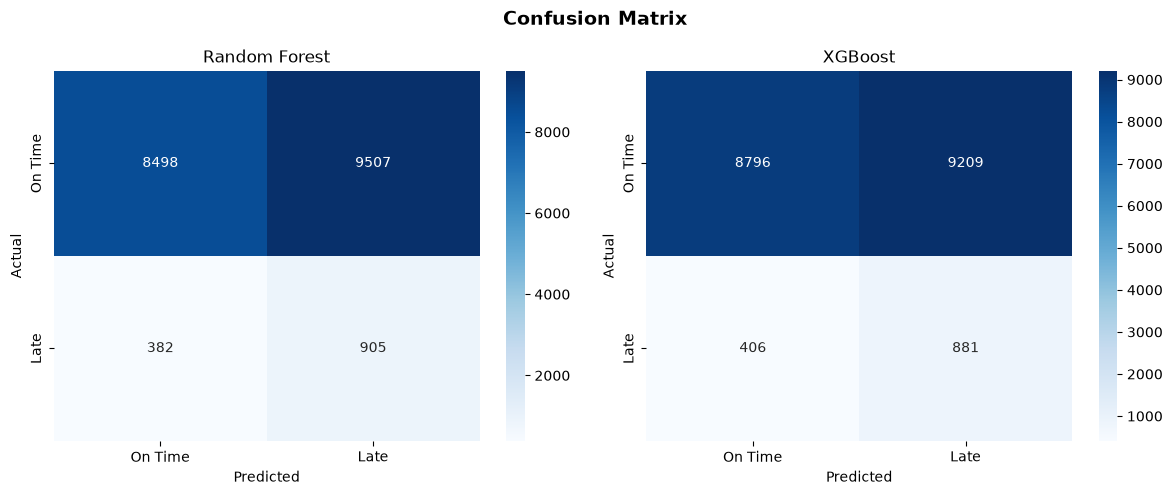

In [31]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Confusion Matrix", fontsize=14, fontweight="bold")

for ax, (name, model) in zip(axes, final_models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["On Time", "Late"],
        yticklabels=["On Time", "Late"],
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

#### Feature Importance

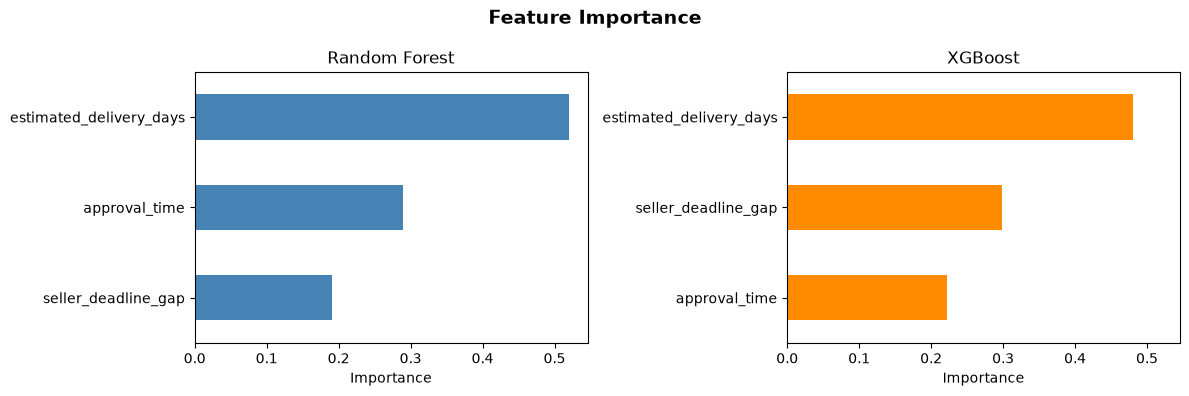

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)
fig.suptitle("Feature Importance", fontsize=14, fontweight="bold")

for ax, (name, model), color in zip(axes, final_models.items(), ["steelblue", "darkorange"]):
    importance = pd.Series(model.feature_importances_, index=X_train.columns).sort_values()
    importance.plot(kind="barh", ax=ax, color=color)
    ax.set_title(name)
    ax.set_xlabel("Importance")

plt.tight_layout()
plt.show()